# Canal 2 -- WHICH SOURCE of uncertainty ranks the error best?

The `canal2_uncertainty_vs_error_classic*.ipynb` notebooks ask the question for **one** source at a time. This one puts the sources side by side, on the same question, the same axes and the same three error cases.

Four sources, produced by the five modes of the same script:

| source | what it measures | where it comes from |
|---|---|---|
| **own head** | what the model emits itself (`pred_var`, or `μ + αμ²`) | `--run-dir` |
| **MC-dropout** | disagreement across T dropout draws | `--mc-dropout-dir` |
| **Laplace** | last-layer posterior variance, closed form | `--laplace-dir` |
| **deep ensemble** | disagreement across M trained seeds | `--ensemble-dir` |

## Two things to know before reading the numbers

**1. The training arms are not all the same.** MC-dropout and Laplace are derived from the **`pr_classic1` weights**: they replay forward passes on that checkpoint. The own head, for its part, is read on `pr_classic3`. Now `pr_classic1` and `pr_classic3` are two **launches of the same sweep**, same configuration and same splits, whose measured gap is ~0.002 (0.0007 to 0.0047). Negligible next to a between-source gap on the order of 0.05, not next to a gap of 0.005. The deep ensemble comes from `de_6`, another training run (several seeds): comparing it to the three others mixes the estimator and the checkpoint. That is unavoidable, an ensemble does not exist without retraining, but it must be said.

**2. Epistemic uncertainty is NOT a function of the predicted mean**, unlike the own head of a count model (Poisson: `u = μ` exactly; NB with per-gene dispersion: `u` monotone in `μ` within a gene). Direct consequence: the heads that are **mute** in own-head mode **become measurable again** here. That is the main reason this comparison exists, and section 4 tests it against the data instead of assuming it.

Reminder of the three error cases and the two axes: see `canal2_uncertainty_vs_error_classic.ipynb`, whose aggregation cascade this notebook reuses identically.

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt

PROJ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.append(str(PROJ))
from src.evaluation.benchmark_summary import donor_lopo_stats

# ════════════════════════════ SETTINGS ════════════════════════════════
DATASETS = ["10x_TuPro", "TLS", "LUNG_CANCER"]
RADIUS   = "r75"

# The 7 heads that carry both post-hoc estimators under pr_classic1 AND the de_6 members.
# The LEAF carries the lambda_ segment for the Gaussian family in the single-model tree, and
# nothing at all for the count family -- exactly as the results tree stores it.
MODEL_LEAF = {
    "heteroscedastic":                      "heteroscedastic/lambda_0.0",
    "homoscedastic":                        "homoscedastic/lambda_0.0",
    "spot_homoscedastic":                   "spot_homoscedastic/lambda_0.0",
    "poisson_cp":                           "poisson_cp",
    "negativebinomial_hetero_noanchor_cp":  "negativebinomial_hetero_noanchor_cp",
    "poisson_raw":                          "poisson_raw",
    "negativebinomial_hetero_noanchor_raw": "negativebinomial_hetero_noanchor_raw",
}
MODELS     = list(MODEL_LEAF)
RAW_MODELS = ["poisson_raw", "negativebinomial_hetero_noanchor_raw"]

# One row per SOURCE. `sub` is the canal2 subfolder (== the mode's default --out-dir), and
# `ens` says whether the leaf goes through .../ensemble/ with NO lambda_ segment (lambda is
# constant across members and disappears from the path on the ensemble side).
# ONE canal at a time. Mixing total and epistemic in one figure makes it unreadable
# AND compares two different questions: `total` is the like-for-like comparison with the own
# head, which already conflates the two components, while `epistemic` alone asks which of the
# two does the ranking. Re-run the notebook with the other value for the other question.
CHANNEL = "epistemic"          # "total" | "epistemic" | "aleatoric"
_SUB_MC  = {"total": "canal2_total_mc", "epistemic": "canal2_epistemic",
            "aleatoric": "canal2_aleatoric_mc"}
SOURCES = [
    dict(key="own", label="pr_classic3", run_id="pr_classic3", ens=False,
         sub="canal2_uncertainty",             name="own head"),
    dict(key="mc",  label="pr_classic1", run_id="pr_classic1", ens=False,
         sub=_SUB_MC[CHANNEL],                 name=f"MC-dropout ({CHANNEL})"),
    dict(key="lap", label="pr_classic1", run_id="pr_classic1", ens=False,
         sub=f"canal2_laplace_{CHANNEL}",      name=f"Laplace ({CHANNEL})"),
    dict(key="de",  label="de_6",        run_id="de_6",        ens=True,
         sub=f"canal2_uncertainty/{CHANNEL}",  name=f"Deep Ensemble ({CHANNEL})"),
]
MAIN_CASE = "lin_pos"        # the case shown by sections 1, 2 and 5
FIGDIR    = PROJ / "results" / "_analysis" / "figures"   # convention canal 1
# ═════════════════════════════════════════════════════════════════════════════

N_PLUS_MIN = 60
CONVENTION = "v3_native_scale"
CASES = ["lin_all", "lin_pos", "log_pos"]
CASE_LABELS = {"lin_all": "|y - mu|  all entries (zeros included)",
               "lin_pos": "|y - mu|  y > 0",
               "log_pos": "|log y - log mu|  y > 0"}
N_COL = {"lin_all": "n_plus_all", "lin_pos": "n_plus_pos", "log_pos": "n_plus_pos"}
AXES = ["gene", "spot"]

MODEL_LABELS = {
    "homoscedastic":                        "Gaussian gene-homoscedastic",
    "heteroscedastic":                      "Gaussian heteroscedastic",
    "spot_homoscedastic":                   "Gaussian spot-homoscedastic",
    "poisson_cp":                           "Poisson",
    "negativebinomial_hetero_noanchor_cp":  "Negative binomial",
    "poisson_raw":                          "Poisson (raw counts)",
    "negativebinomial_hetero_noanchor_raw": "Negative binomial (raw counts)",
}
DATASET_LABELS = {"10x_TuPro": "Tumor Profiler", "TLS": "Kidney/Lung with TLS",
                  "LUNG_CANCER": "NSCLC"}
# One color per SOURCE here (and not per model): it is the source that is compared.
# The three post-hoc estimators reuse the canonical estimator palette:
# the matplotlib base colors b / g / r, fully saturated, so they read at equal visual
# weight. The own head keeps a neutral gray, it is the reference and not an estimator.
# KNOWN COLLISION, and the condition that notebook sets is met here: these are the saturated
# twins of the tab10 blue / green / red that elsewhere denote gene-homoscedastic,
# spot-homoscedastic and Poisson. The palette is only valid in a figure where NO model is
# encoded by a color -- here the models are the ROWS, named on the y axis, and the color
# encodes only the source. Do not carry this palette into a figure where the models are.
SOURCE_COLORS = {"own": "#444444", "mc": "b", "lap": "g", "de": "r"}

DONOR_MAP = yaml.safe_load((PROJ / "snake" / "config" / "donor_slide_map.yaml").read_text())

def slide_to_donor(ds):
    m = DONOR_MAP.get(ds) or {}
    return {sl: d for d, slides in m.items() for sl in slides}


def canal2_dir(src, ds, model):
    """The canal2 folder of a (source, cohort, head). Three path families, not one:
    the single-model tree carries a lambda_ segment for the Gaussians, the ensemble tree goes
    through .../ensemble/ and carries none."""
    base = (PROJ / "results" / ds / src["run_id"]
            / f"_{ds}_hvg_top3000" / RADIUS)
    leaf = model if src["ens"] else MODEL_LEAF[model]
    return (base / leaf / "ensemble" / src["sub"]) if src["ens"] else (base / leaf / src["sub"])


# ── inventory ─────────────────────────────────────────────────────────────────────────────────
SUMM, PAIR, SPOT, missing, stale, na = {}, {}, {}, [], [], []
for src in SOURCES:
    for ds in DATASETS:
        for m in MODELS:
            d = canal2_dir(src, ds, m)
            if not (d / "summary.json").is_file():
                missing.append((src["key"], ds, m))
                continue
            s = json.loads((d / "summary.json").read_text())
            if s.get("not_applicable"):
                na.append((src["key"], ds, m))
                continue
            if s.get("canal2_convention") != CONVENTION:
                stale.append((src["key"], ds, m, s.get("canal2_convention")))
                continue
            k = (src["key"], ds, m)
            SUMM[k] = s
            if (d / "pair_partial.parquet").is_file():
                PAIR[k] = pd.read_parquet(d / "pair_partial.parquet")
            if (d / "spot_partial.parquet").is_file():
                SPOT[k] = pd.read_parquet(d / "spot_partial.parquet")

print("=" * 110)
print("INVENTORY -- how many (cohort, head) per source, out of a maximum of "
      f"{len(DATASETS) * len(MODELS)}")
print("=" * 110)
for src in SOURCES:
    got = sum(1 for (k, _, _) in SUMM if k == src["key"])
    print(f"  {src['name']:<28s} {src['label']:<13s} {src['sub']:<34s} {got:>2d} run(s)")

# The sources do not necessarily come from the same training run. Say it HERE, from the data,
# rather than in a comment: a gap between two sources from DIFFERENT arms mixes
# the estimator and the checkpoint, and the reader of the output must know it without having
# to go read the configuration.
_arms = sorted({s['label'] for s in SOURCES})
if len(_arms) > 1:
    print(f"\n(!) The sources come from {len(_arms)} training arms: {_arms}")
    for a in _arms:
        print(f"      {a:<13s} : {[s['key'] for s in SOURCES if s['label'] == a]}")
    print("    pr_classic1 and pr_classic3 are two LAUNCHES of the same sweep, not")
    print("    the same weights. a dedicated comparison measures their gap")
    print("    at ~0.002 (0.0007 to 0.0047) on the point estimates quoted. Negligible next")
    print("    to a between-source gap on the order of 0.05; not to a gap of 0.005.")
if stale:
    print(f"\n(!) {len(stale)} run(s) NOT conforming to canal2_convention={CONVENTION!r} -- DROPPED.")
    print("    Their columns are not the ones read here; re-run canal2 on them.")
    for k, ds, m, c in stale[:12]:
        print(f"    {k:<9s} {ds:<12s} {m:<40s} convention read : {c!r}")
    if len(stale) > 12:
        print(f"    ... and {len(stale) - 12} more")
if na:
    print(f"\n{len(na)} run(s) 'not_applicable' (canal 2 does not apply there): {na[:6]}")
if missing:
    print(f"\n(!) {len(missing)} (source, cohort, head) with NO summary.json -- the precompute did"
          f" not run there:")
    for k in sorted({x[0] for x in missing}):
        w = [f"{ds}/{m}" for (kk, ds, m) in missing if kk == k]
        print(f"    {k:<9s} {len(w):>2d} missing: {w[:4]}{' ...' if len(w) > 4 else ''}")

INVENTORY -- how many (cohort, head) per source, out of a maximum of 21
  own head                     pr_classic3   canal2_uncertainty                 21 run(s)
  MC-dropout (epistemic)       pr_classic1   canal2_epistemic                   21 run(s)
  Laplace (epistemic)          pr_classic1   canal2_laplace_epistemic           21 run(s)
  Deep Ensemble (epistemic)    de_6          canal2_uncertainty/epistemic       21 run(s)

(!) The sources come from 3 training arms: ['de_6', 'pr_classic1', 'pr_classic3']
      de_6          : ['de']
      pr_classic1   : ['mc', 'lap']
      pr_classic3   : ['own']
    pr_classic1 and pr_classic3 are two LAUNCHES of the same sweep, not
    the same weights. a dedicated comparison measures their gap
    at ~0.002 (0.0007 to 0.0047) on the point estimates quoted. Negligible next
    to a between-source gap on the order of 0.05; not to a gap of 0.005.


## 1. The result: the sources side by side

Same cascade as the single-source notebook, identically, with the donor boundary as the only addition: per group → gene (weighted by n) → donor → K points → Student-t on the gene axis; plain mean over the donor's spots on the spot axis.

What to look at, in order:

1. **The controlled column**, never the naive one. The naive one mostly measures the uncertainty ↔ mean coupling, and it differs from one source to another, so it would rank them on that coupling rather than on their informativeness.
2. **The heads mute in `own head` that speak elsewhere.** `poisson_cp` has no free parameter of its own (`u = μ`) but has a perfectly well-defined epistemic uncertainty. A value where the own head is mute is a result, not a bug.
3. **`total` against `epistemic`.** `total` is the like-for-like comparison with the own head, which already conflates the two components. `epistemic` alone answers a narrower question: is it the disagreement between models, or the learned predictive variance, that does the ranking?

`*` = the Student-t interval over donors excludes zero.

In [2]:
def donor_points(frame, ds, axis, case, stat):
    """{donor: value} + the number of groups kept. Cascade identical to the script's;
    only the donor boundary is added."""
    col, ncol = f"{stat}_{case}", N_COL[case]
    if frame is None or col not in frame.columns or ncol not in frame.columns:
        return {}, 0
    d = frame[(frame[ncol] >= N_PLUS_MIN) & frame[col].notna()]
    if d.empty:
        return {}, 0
    s2d = slide_to_donor(ds)
    donor = d["slide"].map(lambda s: s2d.get(s, s))
    if axis == "spot":                       # one spot = one slide = one donor
        return d.groupby(donor.to_numpy())[col].mean().to_dict(), int(len(d))
    g = pd.DataFrame({"gene": d["gene"].to_numpy(), "donor": donor.to_numpy(),
                      "w": d[col].to_numpy() * d[ncol].to_numpy(),
                      "n": d[ncol].to_numpy()}).groupby(["gene", "donor"], as_index=False).sum()
    g["v"] = g["w"] / g["n"]
    return g.groupby("donor")["v"].mean().to_dict(), int(len(d))


rows = []
for (key, ds, m) in SUMM:
    for case in CASES:
        for axis in AXES:
            frame = (PAIR if axis == "gene" else SPOT).get((key, ds, m))
            rec = dict(source=key, dataset=ds, model=m, case=case, axis=axis)
            for stat, tag in (("r_uD", "naive"), ("r_partial", "partial")):
                pts, n = donor_points(frame, ds, axis, case, stat)
                if not pts:
                    continue
                st = donor_lopo_stats(pts)
                rec.update({tag: st["mean"], f"{tag}_lo": st["ci95_mean"][0],
                            f"{tag}_hi": st["ci95_mean"][1], "K": st["K"], f"{tag}_n": n})
            rows.append(rec)
RES = pd.DataFrame(rows)


def get(key, ds, m, case, axis):
    r = RES[(RES["source"] == key) & (RES["dataset"] == ds) & (RES["model"] == m)
            & (RES["case"] == case) & (RES["axis"] == axis)] if not RES.empty else RES
    return None if r.empty else r.iloc[0]


def cell(r, tag, width=26):
    if r is None:
        return f"{'absent':>{width}s}"
    v = r.get(tag, np.nan)
    if not np.isfinite(v):
        return f"{'mute':>{width}s}"
    lo, hi = r.get(f"{tag}_lo", np.nan), r.get(f"{tag}_hi", np.nan)
    if not np.isfinite(lo):
        return f"{v:>+{width}.4f}"
    star = "*" if (lo > 0 or hi < 0) else " "
    return f"{v:+.4f} [{lo:+.4f},{hi:+.4f}]{star}".rjust(width)


for axis in AXES:
    print("\n" + "#" * 126)
    print(f"# {axis.upper()} AXIS -- case {MAIN_CASE} ({CASE_LABELS[MAIN_CASE]})")
    print("#   'mute' = partial undefined by construction.  'absent' = precompute not run.")
    print("#" * 126)
    for ds in DATASETS:
        print(f"\n--- {DATASET_LABELS.get(ds, ds)} ---")
        print(f"  {'head':<40s} " + " ".join(f"{s['name'][:24]:>26s}" for s in SOURCES))
        for m in MODELS:
            cells = " ".join(cell(get(s["key"], ds, m, MAIN_CASE, axis), "partial")
                             for s in SOURCES)
            if all("absent" in c for c in cells.split()):
                continue
            print(f"  {MODEL_LABELS.get(m, m):<40s} {cells}")

print("\n" + "=" * 126)
print("THE SAME TABLE, NAIVE VALUE -- NOT to be used to rank the sources: it mostly measures")
print("the uncertainty/mean coupling, which differs from one source to another.")
print("=" * 126)
for ds in DATASETS:
    print(f"\n--- {DATASET_LABELS.get(ds, ds)}  (gene axis, {MAIN_CASE}) ---")
    print(f"  {'head':<40s} " + " ".join(f"{s['name'][:24]:>26s}" for s in SOURCES))
    for m in MODELS:
        cells = " ".join(cell(get(s["key"], ds, m, MAIN_CASE, "gene"), "naive") for s in SOURCES)
        if all("absent" in c for c in cells.split()):
            continue
        print(f"  {MODEL_LABELS.get(m, m):<40s} {cells}")


##############################################################################################################################
# GENE AXIS -- case lin_pos (|y - mu|  y > 0)
#   'mute' = partial undefined by construction.  'absent' = precompute not run.
##############################################################################################################################

--- Tumor Profiler ---
  head                                                       own head     MC-dropout (epistemic)        Laplace (epistemic)   Deep Ensemble (epistemic
  Gaussian heteroscedastic                 +0.1156 [+0.0683,+0.1629]* +0.0589 [+0.0102,+0.1076]* +0.0657 [+0.0182,+0.1133]* +0.0229 [+0.0005,+0.0452]*
  Gaussian gene-homoscedastic                                    mute +0.0417 [+0.0160,+0.0674]* +0.0645 [+0.0210,+0.1079]* +0.0203 [+0.0028,+0.0379]*
  Gaussian spot-homoscedastic              +0.1258 [+0.0832,+0.1684]* +0.0726 [+0.0325,+0.1127]* +0.0364 [-0.0347,+0.1075]  +0.0321 [+0.0129,+

## 2. The figure

One panel per cohort, one row per head, one marker per source with its Student-t interval over donors. Mute or absent heads simply leave nothing at their position: that is information, not a data hole.

The `_raw` heads are **excluded from the figure**: their error is measured against a target that carries the spot's library size, that is a different error axis. They stay in the tables above, where they read against each other.

The plotted numbers are reprinted below.

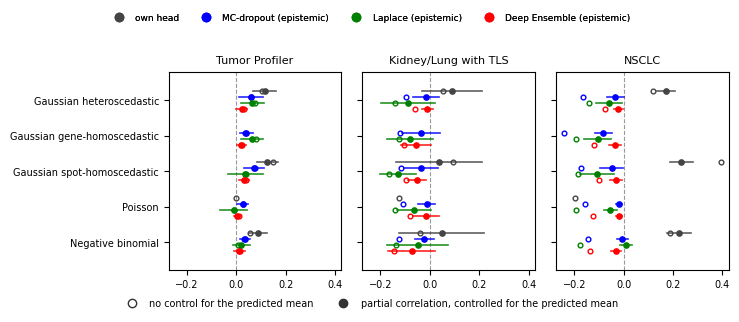

## FIGURE  fig_canal2_sources_gene_axis_lin_pos.pdf
## TITLE   Which source of predictive uncertainty ranks the prediction error best, on the gene axis
## CAPTION Error definition: |y - mu|, detected entries only (y > 0).
## CAPTION One row per predictive head, one marker per uncertainty source (color). Each
## CAPTION marker is a source (color); hollow = no control, filled = partial correlation
## CAPTION between that source and the absolute error,
## CAPTION error within a group, the predicted mean being partialled out as a rank
## CAPTION covariate. Bar: Student-t 95% interval over the held-out donors.
## CAPTION A source missing on a row is MUTE there by construction, not absent from the
## CAPTION data: its uncertainty carries no degree of freedom independent of the mean.
## CAPTION Own head, MC-dropout and Laplace read one training arm, the deep ensemble
## CAPTION another, so the ensemble comparison mixes estimator and checkpoint.
## CAPTION Depth-blind heads are excluded: their

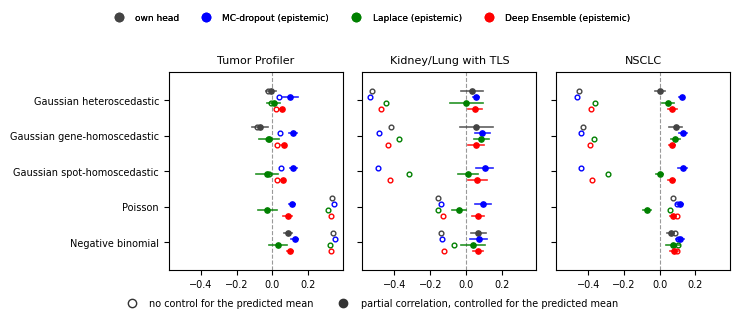

## FIGURE  fig_canal2_sources_spot_axis_lin_pos.pdf
## TITLE   Which source of predictive uncertainty ranks the prediction error best, on the spot axis
## CAPTION Error definition: |y - mu|, detected entries only (y > 0).
## CAPTION One row per predictive head, one marker per uncertainty source (color). Each
## CAPTION marker is a source (color); hollow = no control, filled = partial correlation
## CAPTION between that source and the absolute error,
## CAPTION error within a group, the predicted mean being partialled out as a rank
## CAPTION covariate. Bar: Student-t 95% interval over the held-out donors.
## CAPTION A source missing on a row is MUTE there by construction, not absent from the
## CAPTION data: its uncertainty carries no degree of freedom independent of the mean.
## CAPTION Own head, MC-dropout and Laplace read one training arm, the deep ensemble
## CAPTION another, so the ensemble comparison mixes estimator and checkpoint.
## CAPTION Depth-blind heads are excluded: their

In [3]:
from matplotlib.lines import Line2D

CASE_FIG = {"lin_all": "|y - mu|, all (spot, gene) entries, zeros included",
            "lin_pos": "|y - mu|, detected entries only (y > 0)",
            "log_pos": "|log y - log mu|, detected entries only (y > 0)"}

def fig_show(fig, stem, title, caption):
    fig.savefig(f"{stem}.pdf", bbox_inches="tight")
    fig.savefig(f"{stem}.png", dpi=300, bbox_inches="tight")
    plt.show()
    print(f"## FIGURE  {stem.name}.pdf")
    print(f"## TITLE   {title}")
    for line in caption:
        print(f"## CAPTION {line}")

FIGDIR.mkdir(parents=True, exist_ok=True)
PLOT_MODELS = [m for m in MODELS if m not in RAW_MODELS]

drawn = []
for axis in AXES:
    fig, axarr = plt.subplots(1, len(DATASETS), figsize=(2.5 * len(DATASETS), 3.0),
                              sharex=True, squeeze=False)
    for j, ds in enumerate(DATASETS):
        ax = axarr[0, j]
        for i, m in enumerate(PLOT_MODELS):
            for k, s in enumerate(SOURCES):
                r = get(s["key"], ds, m, MAIN_CASE, axis)
                if r is None:
                    continue
                # vertical offset per source, so that the intervals do not overlap
                y = i + (k - (len(SOURCES) - 1) / 2) * 0.17
                c = SOURCE_COLORS.get(s["key"], "0.5")
                nv, pv = r.get("naive", np.nan), r.get("partial", np.nan)
                # Same convention as everywhere else: HOLLOW = uncontrolled, FILLED = controlled,
                # interval on the controlled one only. A source with no filled marker is MUTE
                # on that axis by construction, and its hollow marker says where it started.
                if np.isfinite(nv):
                    ax.plot([nv], [y], "o", ms=3.4, mfc="none", mec=c, mew=1.0, zorder=3)
                if not np.isfinite(pv):
                    continue
                lo, hi = r.get("partial_lo", np.nan), r.get("partial_hi", np.nan)
                if np.isfinite(lo):
                    ax.plot([lo, hi], [y, y], color=c, lw=1.2, alpha=0.85, zorder=3)
                ax.plot([pv], [y], "o", color=c, ms=3.8, zorder=4)
                drawn.append(dict(axis=axis, dataset=ds, model=m, source=s["key"],
                                  partial=r["partial"], lo=lo, hi=hi))
        ax.axvline(0.0, color="0.6", lw=0.8, ls="--", zorder=1)
        ax.set_yticks(range(len(PLOT_MODELS)))
        ax.set_yticklabels([MODEL_LABELS.get(m, m) for m in PLOT_MODELS] if j == 0 else [],
                           fontsize=6.5)
        ax.invert_yaxis()
        ax.margins(y=0.12)
        ax.tick_params(labelsize=7)
        ax.set_title(DATASET_LABELS.get(ds, ds), fontsize=8)
    handles = [Line2D([], [], marker="o", ls="", color=SOURCE_COLORS.get(s["key"], "0.5"),
                      label=s["name"]) for s in SOURCES]
    cond = [Line2D([], [], marker="o", ls="", mfc="none", mec="#333333", mew=1.0,
                   label="no control for the predicted mean"),
            Line2D([], [], marker="o", ls="", color="#333333",
                   label="partial correlation, controlled for the predicted mean")]
    fig.tight_layout(rect=(0, 0, 1, 0.88))
    leg1 = fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 1.0),
                      ncol=4, frameon=False, fontsize=6.5)
    fig.add_artist(leg1)
    fig.legend(handles=cond, loc="lower center", ncol=2, frameon=False, fontsize=7,
               bbox_to_anchor=(0.5, -0.04))
    fig_show(fig, FIGDIR / f"fig_canal2_sources_{axis}_axis_{MAIN_CASE}",
             f"Which source of predictive uncertainty ranks the prediction error best, on the "
             f"{axis} axis",
             [f"Error definition: {CASE_FIG[MAIN_CASE]}.",
              "One row per predictive head, one marker per uncertainty source (color). Each",
              "marker is a source (color); hollow = no control, filled = partial correlation",
              "between that source and the absolute error,",
              "error within a group, the predicted mean being partialled out as a rank",
              "covariate. Bar: Student-t 95% interval over the held-out donors.",
              "A source missing on a row is MUTE there by construction, not absent from the",
              "data: its uncertainty carries no degree of freedom independent of the mean.",
              "Own head, MC-dropout and Laplace read one training arm, the deep ensemble",
              "another, so the ensemble comparison mixes estimator and checkpoint.",
              "Depth-blind heads are excluded: their error lives on a different axis."])

D = pd.DataFrame(drawn)
print("\n" + "=" * 112)
print("THE PRINTED TWIN OF BOTH FIGURES")
print("=" * 112)
for axis in AXES:
    for ds in DATASETS:
        sub = D[(D["axis"] == axis) & (D["dataset"] == ds)] if not D.empty else D
        if sub.empty:
            continue
        print(f"\n[{axis} axis | {DATASET_LABELS.get(ds, ds)}]")
        for _, r in sub.iterrows():
            ci = f"[{r['lo']:+.4f}, {r['hi']:+.4f}]" if np.isfinite(r["lo"]) else "n/a"
            print(f"    {MODEL_LABELS.get(r['model'], r['model']):<40s} "
                  f"{r['source']:<8s} {r['partial']:>+9.4f} {ci:>22s}")

## 3. Does the source ranking depend on the error case?

A comparison of sources is only worth something if it survives the choice of the error definition. So the same table is redone over the three cases and the two axes, looking at **which source comes out on top** each time.

If the same source wins everywhere, the conclusion is robust and is reported as is. If the winner changes with the case or with the axis, there is no "best source" to report, and it is that finding which must be written, not a ranking picked among the convenient ones.

⚠️ `lin_all` is included for completeness, but its naive value is mechanical (at `y = 0` the error IS `|mu|`) and its partial on the spot axis is ill-conditioned (`r_Dm` close to 1 by construction). To be treated as a demonstration of the confounder, not as a fourth measurement.

In [4]:
print("=" * 126)
print("WHICH SOURCE COMES OUT ON TOP (highest CONTROLLED value), per (cohort, head, case, axis)")
print("=" * 126)
wins = []
for ds in DATASETS:
    for m in MODELS:
        for case in CASES:
            for axis in AXES:
                vals = {s["key"]: get(s["key"], ds, m, case, axis) for s in SOURCES}
                vals = {k: r["partial"] for k, r in vals.items()
                        if r is not None and np.isfinite(r.get("partial", np.nan))}
                if len(vals) < 2:
                    continue
                best = max(vals, key=vals.get)
                wins.append(dict(dataset=ds, model=m, case=case, axis=axis, best=best,
                                 value=vals[best], n_sources=len(vals),
                                 spread=max(vals.values()) - min(vals.values())))
W = pd.DataFrame(wins)
if W.empty:
    print("  fewer than two comparable sources: nothing to rank.")
else:
    print(f"\n  {len(W)} comparisons with at least two sources\n")
    print("  -- how many times each source comes out on top --")
    for k, c in W["best"].value_counts().items():
        nm = next(s["name"] for s in SOURCES if s["key"] == k)
        print(f"    {nm:<28s} {c:>3d} / {len(W)}")
    print("\n  -- per case and per axis, to see if the winner depends on the choice --")
    piv = W.pivot_table(index=["case", "axis"], columns="best", values="value",
                        aggfunc="count").fillna(0).astype(int)
    print(piv.to_string())
    print("\n  -- gap between the best and the worst source, per (case, axis) --")
    print("     a small gap means that the choice of source does not change much")
    print(W.groupby(["case", "axis"])["spread"].describe()[["count", "50%", "max"]]
           .rename(columns={"50%": "median gap", "max": "max gap"}).round(4).to_string())

print("\n" + "=" * 126)
print("THE DETAIL: the CONTROLLED value, all cases and all axes, one cohort at a time")
print("=" * 126)
for ds in DATASETS:
    for case in CASES:
        for axis in AXES:
            lines = []
            for m in MODELS:
                cs = " ".join(cell(get(s["key"], ds, m, case, axis), "partial", 15) for s in SOURCES)
                if "absent" in cs and cs.count("absent") == len(SOURCES):
                    continue
                lines.append(f"    {MODEL_LABELS.get(m, m):<40s} {cs}")
            if not lines:
                continue
            print(f"\n[{DATASET_LABELS.get(ds, ds)} | {case} | {axis} axis]")
            print(f"    {'head':<40s} " + " ".join(f"{s['key']:>15s}" for s in SOURCES))
            print("\n".join(lines))

WHICH SOURCE COMES OUT ON TOP (highest CONTROLLED value), per (cohort, head, case, axis)

  126 comparisons with at least two sources

  -- how many times each source comes out on top --
    MC-dropout (epistemic)        52 / 126
    own head                      32 / 126
    Laplace (epistemic)           31 / 126
    Deep Ensemble (epistemic)     11 / 126

  -- per case and per axis, to see if the winner depends on the choice --
best          de  lap  mc  own
case    axis                  
lin_all gene   0   12   4    5
        spot   2    4  11    4
lin_pos gene   3    6   3    9
        spot   2    1  17    1
log_pos gene   2    5   4   10
        spot   2    3  13    3

  -- gap between the best and the worst source, per (case, axis) --
     a small gap means that the choice of source does not change much
              count  median gap  max gap
case    axis                            
lin_all gene   21.0      0.0149   0.0483
        spot   21.0      0.0738   0.1525
lin_pos gene   

## 4. What the post-hoc sources unlock: the degeneracy lifted

This is the structural reason this comparison exists, and it can be tested.

A model's own head is **degenerate** on the axis where its variance parameter is constant: `u` is constant there or a monotone function of `mu`, `r_um = ±1`, the partial is undefined. Poisson is mute on BOTH axes (`u = μ` exactly, no free parameter).

**Epistemic** uncertainty does not come from a variance head: it is the disagreement across dropout draws, across seeds, or a last-layer posterior variance. So it is not a function of `mu`, and the heads mute in own-head mode must **become measurable again**.

The cell tests this prediction against the data: it counts, per source, the (cohort, head) where the partial is defined. If Poisson stays mute on a post-hoc source, that is not a property of the head, it is a problem to understand.

In [5]:
print("=" * 126)
print("WHERE IS THE PARTIAL DEFINED? (case lin_pos; the degeneracy does not depend on the error")
print("definition, only on u)   V = defined, . = mute, - = precompute absent")
print("=" * 126)
for axis in AXES:
    print(f"\n[{axis} axis]")
    print(f"  {'head':<40s} {'cohort':<14s} " + " ".join(f"{s['key']:>9s}" for s in SOURCES))
    for m in MODELS:
        for ds in DATASETS:
            marks = []
            for s in SOURCES:
                r = get(s["key"], ds, m, "lin_pos", axis)
                marks.append("-" if r is None
                             else ("V" if np.isfinite(r.get("partial", np.nan)) else "."))
            if all(x == "-" for x in marks):
                continue
            print(f"  {MODEL_LABELS.get(m, m):<40s} {ds:<14s} "
                  + " ".join(f"{x:>9s}" for x in marks))

print("\n" + "=" * 126)
print("THE PREDICTION, TESTED: does a head mute in OWN HEAD speak on a post-hoc source?")
print("=" * 126)
unlocked = mute_everywhere = 0
for ds in DATASETS:
    for m in MODELS:
        for axis in AXES:
            own = get("own", ds, m, "lin_pos", axis)
            if own is None or np.isfinite(own.get("partial", np.nan)):
                continue                       # not mute in own head: nothing to unlock
            others = {s["key"]: get(s["key"], ds, m, "lin_pos", axis)
                      for s in SOURCES if s["key"] != "own"}
            alive = {k: r["partial"] for k, r in others.items()
                     if r is not None and np.isfinite(r.get("partial", np.nan))}
            if alive:
                unlocked += 1
                vals = "  ".join(f"{k}={v:+.4f}" for k, v in alive.items())
                print(f"  UNLOCKED  {ds:<12s} {m:<40s} axis {axis:<5s} {vals}")
            else:
                mute_everywhere += 1
                print(f"  (!) MUTE EVERYWHERE  {ds:<12s} {m:<40s} axis {axis:<5s} "
                      f"-- expected only if no post-hoc source ran here")
print(f"\n  {unlocked} cases unlocked by a post-hoc source, {mute_everywhere} left mute.")

WHERE IS THE PARTIAL DEFINED? (case lin_pos; the degeneracy does not depend on the error
definition, only on u)   V = defined, . = mute, - = precompute absent

[gene axis]
  head                                     cohort               own        mc       lap        de
  Gaussian heteroscedastic                 10x_TuPro              V         V         V         V
  Gaussian heteroscedastic                 TLS                    V         V         V         V
  Gaussian heteroscedastic                 LUNG_CANCER            V         V         V         V
  Gaussian gene-homoscedastic              10x_TuPro              .         V         V         V
  Gaussian gene-homoscedastic              TLS                    .         V         V         V
  Gaussian gene-homoscedastic              LUNG_CANCER            .         V         V         V
  Gaussian spot-homoscedastic              10x_TuPro              V         V         V         V
  Gaussian spot-homoscedastic              T

## 5. Sparsification, per source

The operational version of the same question: sort by uncertainty, drop the `f` most uncertain, look at the mean error of the rest. The **stratified** curve drops within each group (gene, slide, mu bin), so the composition does not drift: it is the operational analogue of the partial correlation, as the pooled one is of the naive one.

**AUSE** = area under the curve normalized by its starting point. A non-informative sort is exactly 1.0, lower is better. The **captured share** = `(1 − AUSE) / (1 − AUSE_oracle)`, i.e. the fraction of the attainable gain that the source actually goes and gets -- it is the number that best compares sources with one another, because it is normalized by what was possible on that cohort.

Population: `y > 0` and groups that have a regime. Pooled mean over the cohort, so **no per-donor interval here**.

In [6]:
def ause(curve):
    c = np.asarray(curve, dtype=float)
    if c.size == 0 or not np.isfinite(c[0]) or c[0] == 0:
        return float("nan")
    return float(np.nanmean(c / c[0]))


rows = []
for src in SOURCES:
    for ds in DATASETS:
        for m in MODELS:
            if (src["key"], ds, m) not in SUMM:
                continue
            p = canal2_dir(src, ds, m) / "sparsification.parquet"
            if not p.is_file():
                continue
            sp = pd.read_parquet(p)
            need = [f"curve_pred_stratified_{MAIN_CASE}", f"curve_oracle_stratified_{MAIN_CASE}"]
            if any(c not in sp.columns for c in need):
                continue
            a, o = ause(sp[need[0]].to_numpy()), ause(sp[need[1]].to_numpy())
            share = (1 - a) / (1 - o) if np.isfinite(o) and abs(1 - o) > 1e-9 else np.nan
            cur = sp[need[0]].to_numpy()
            fr = sp["frac"].to_numpy()
            k25 = int(np.argmin(np.abs(fr - 0.25)))
            rows.append(dict(source=src["key"], dataset=ds, model=m, ause=a, ause_oracle=o,
                             share=share,
                             drop25=100 * (1 - cur[k25] / cur[0]) if cur[0] else np.nan))
A = pd.DataFrame(rows)

print("=" * 126)
print(f"STRATIFIED SPARSIFICATION, case {MAIN_CASE} -- captured share of the oracle (higher = better)")
print("  drop25 = fall in the mean error after dropping the 25 % most uncertain")
print("=" * 126)
if A.empty:
    print("  no readable sparsification.parquet.")
else:
    for ds in DATASETS:
        sub = A[A["dataset"] == ds]
        if sub.empty:
            continue
        print(f"\n--- {DATASET_LABELS.get(ds, ds)} ---")
        print(f"  {'head':<40s} " + " ".join(f"{s['key']:>16s}" for s in SOURCES))
        for m in MODELS:
            cells = []
            for s in SOURCES:
                r = sub[(sub["source"] == s["key"]) & (sub["model"] == m)]
                cells.append(f"{'-':>16s}" if r.empty
                             else f"{r.iloc[0]['share']:>15.1%} ")
            if all(c.strip() == "-" for c in cells):
                continue
            print(f"  {MODEL_LABELS.get(m, m):<40s} " + " ".join(cells))
        print(f"  {'(AUSE oracle, the bound)':<40s} "
              + " ".join(f"{sub[sub['source'] == s['key']]['ause_oracle'].median():>16.4f}"
                         if not sub[sub['source'] == s['key']].empty else f"{'-':>16s}"
                         for s in SOURCES))

STRATIFIED SPARSIFICATION, case lin_pos -- captured share of the oracle (higher = better)
  drop25 = fall in the mean error after dropping the 25 % most uncertain

--- Tumor Profiler ---
  head                                                  own               mc              lap               de
  Poisson                                                 -                -           99.0%                 -
  Negative binomial                                       -                -           96.1%                 -
  Poisson (raw counts)                                6.3%                 -           99.7%                 -
  Negative binomial (raw counts)                      6.5%                 -           91.5%                 -
  (AUSE oracle, the bound)                           0.5352                -           0.1187                -

--- Kidney/Lung with TLS ---
  head                                                  own               mc              lap               de
  Pois

## 6. What must be said when reporting these numbers

**The deep ensemble is not on the same training arm.** MC-dropout and Laplace are derived from the `pr_classic1` weights, the own head is read on `pr_classic3`: two launches of the same sweep, gap measured at ~0.002. `de_6` is a separate multi-seed training run, so the gap with the three others mixes the estimator and the checkpoint. An ensemble does not exist without retraining, that is unavoidable -- but it is not left unsaid.

**`total` and `epistemic` do not answer the same question.** `total` is the like-for-like comparison with the own head, which already conflates aleatoric and epistemic. `epistemic` alone asks which of the two components does the ranking. Do not present one as the other's headline number.

**A mute head is not a missing datum.** The distinction is made explicitly in the tables (`mute` against `absent`) and section 4 tests the structural prediction rather than assuming it.

**The `_raw` heads stay in their own table.** Their error is measured against a target that carries the spot's library size: a different error axis, never the same figure as the `_cp` models and the Gaussians.

**The per-donor intervals are optimistic** (the folds share K−2 training donors, Bengio & Grandvalet 2004). For the per-donor points behind each mean, see `canal2_uncertainty_vs_error_classic.ipynb`, which prints them; the same cascade is used here.